# Research notebook: sensory replenished synapses

**Curated source:** [`notebooks/31_sensory_resource_analytical_calibration.ipynb`](../notebooks/31_sensory_resource_analytical_calibration.ipynb). The experimental code and outputs below are preserved as committed; no claim of equivalence to other historical notebooks is implied.

This is the latest committed SRR comparison. The resource variable is replenished on camera input and depleted by recurrent firing; excitatory transmission is additive. Keep its independently derived operating-region assumptions and the actual Brian2 results distinct. A successful development set is not the same as passing held-out geometry tests.

**Supporting evidence and lineage.** Read [30](../notebooks/30_three_factor_stdp_vs_sensory_resources.ipynb) for the original contrast with three-factor STDP; [26](../notebooks/26_escm20_current_balance_diagnostic.ipynb) shows why additive-current accumulation makes competition difficult. Any Brian2 potentially order-dependent resource-update warning must be resolved before taking transmission/depletion order as independently verified.

See [research/index.md](index.md) for the full 31-notebook map and definition of the benchmark variants. Run from an environment with the source notebook's original dependencies. The code cells below have **not been re-executed as part of the reorganization**.

# Notebook 31 — Analytical calibration of sensory-replenished recurrent synapses

## Scientific question

Can a **standard refractory LIF network with additive autaptic excitation** achieve all of the following without an explicit neuronal `support` variable?

1. Camera events replenish the autapse's available resources.
2. Recurrent spikes consume those resources.
3. Refractoriness limits the maximum firing rate.
4. Synaptic currents and membrane potential remain bounded, with activity fading when sensory input stops.
5. Competing spatial representations can suppress obsolete activity while retaining new activity.

We compare a **locked sensory-replenished-resource (SRR) candidate** with the unchanged **ESCM 2.0 + fading** benchmark from Notebook 30. The candidate was obtained using a separate, fast, mathematically equivalent *discrete-time surrogate* for screening—not by running Brian2 on this computer. **The results are preliminary until the Brian2 cells below are executed.**

### Where the candidate came from (selection before validation)

- An exact-linear-step, NumPy/Numba implementation reproduced the approved isolated ESCM 2.0 last spike at **89.2 ms**, and its original two development replacement successes.
- Screened **1,152** SRR combinations. **389** passed a provisional isolated persistence/fading screen measured to **260 ms**.
- Combined these with inhibition gain and decay choices on the **vertical** development geometry. **118** operating points passed its strict 5/5-old-silenced and 5/5-new-active criterion, including the control conditions.
- Selected the strongest candidate by **12 development challenges**: vertical and horizontal geometry, with six onset/stagger combinations each. The locked setting passed **12/12** in the surrogate.
- **No six held-out spatial shapes were used for candidate selection.** They are tested afterward, below.

The high nominal weight $J_0$ should **not** be interpreted as the delivered impulse: the event amplitude is $J_0U x$, initially bounded by $J_0U=6$; $U$ is deliberately small.

**Provisional locked candidate:** $J_0=2400$, $U=0.0025$, $\alpha=0.95$, $\tau_x=350\,\mathrm{ms}$, $\tau_{\rm exc}=3\,\mathrm{ms}$, $\tau_{\rm inh}=7\,\mathrm{ms}$, inhibitory gain $g_I=4$, absolute refractory period $1\,\mathrm{ms}$. All other conditions match Notebook 30.


## 1. Resource equation, bounds, and the operating-region argument

For each autapse, let $x_i\in[0,1]$ be **available resources**, and retain a fixed nominal recurrent weight $J_0$. Between events,

$$\dot x_i=-x_i/\tau_x,\qquad \dot I_{\mathrm{exc},i}=-I_{\mathrm{exc},i}/\tau_{\rm exc}.$$

On a camera event, $x_i^+=x_i^-+\alpha(1-x_i^-)$ and $I_{\rm ext,i}^+=I_{\rm ext,i}^-+22$.

On a recurrent spike, use the **pre-depletion resource** $x_i^-$:

$$\boxed{I_{\mathrm{exc},i}^+=I_{\mathrm{exc},i}^-+J_0U x_i^-,\qquad x_i^+=(1-U)x_i^-.}$$

These operations remain additive at the postsynaptic-current level. No other neuron can restore $x_i$: recurrent spikes only consume it. Camera updates are saturating and preserve $0\leq x_i\leq1$ for $0\leq\alpha,U\leq1$.

After the final camera event at $t_0$, the exact resource trajectory is

$$\boxed{x_i(t)=x_i(t_0^+)e^{-(t-t_0)/\tau_x}(1-U)^{N_i(t_0,t)}}$$

where $N_i(t_0,t)$ counts recurrent spikes since $t_0$. For roughly constant firing rate $r$, this suggests an *effective* depletion time

$$\boxed{\tau_{\mathrm{eff}}^{-1}\simeq \tau_x^{-1}-r\ln(1-U),}$$

where $r$ is measured in spikes per millisecond if the time constants are in ms. This is a **resource timescale**, not a prediction of the final spike time: firing also depends on membrane voltage, current filtering, inhibition, and refractoriness.

Since $0\le x\le1$ and spikes cannot occur closer together than $t_{\rm ref}$, excitatory current has an invariant upper bound (starting from zero)

$$0\le I_{\rm exc}(t)\le \frac{J_0U}{1-\exp(-t_{\rm ref}/\tau_{\rm exc})}.$$

The LIF membrane receives bounded inputs, so its voltage cannot diverge. **Boundedness does not imply good competition**; large bounded currents can still overwhelm inhibition.

We therefore select on independent isolated persistence and development replacement, then evaluate held-out spatial and temporal conditions.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"
print("Brian2 version:", b2.__version__)


/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Brian2 version: 2.10.1


In [2]:
width = height = 9
n = width * height
dt_ms = 0.05
xy = np.column_stack((np.arange(n) % width, np.arange(n) // width))

def pixels(coords):
    return np.array([y*width + x for x, y in coords], dtype=int)

shapes = {
    "vertical": (pixels([(2, y) for y in range(2, 7)]), pixels([(5, y) for y in range(2, 7)])),
    "horizontal": (pixels([(x, 2) for x in range(2, 7)]), pixels([(x, 5) for x in range(2, 7)])),
    "diagonal": (pixels([(x, x) for x in range(1, 6)]), pixels([(x+3, x) for x in range(1, 6)])),
    "L-shaped": (pixels([(2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]),
                 pixels([(5, 2), (5, 3), (5, 4), (6, 4), (7, 4)])),
    "stepped": (pixels([(2, 2), (3, 2), (3, 3), (4, 3), (4, 4)]),
                pixels([(5, 2), (6, 2), (6, 3), (7, 3), (7, 4)])),
    "zigzag": (pixels([(1, 1), (2, 2), (1, 3), (2, 4), (1, 5)]),
               pixels([(5, 1), (6, 2), (5, 3), (6, 4), (5, 5)])),
    "T-junction": (pixels([(2, 2), (3, 2), (4, 2), (3, 3), (3, 4)]),
                   pixels([(5, 2), (6, 2), (7, 2), (6, 3), (6, 4)])),
    "compact cluster": (pixels([(1, 2), (2, 2), (1, 3), (2, 3), (3, 3)]),
                        pixels([(5, 2), (6, 2), (5, 3), (6, 3), (7, 3)])),
}
development = ("vertical", "horizontal")
validation = tuple(name for name in shapes if name not in development)
assert len(validation) == 6
for old, new in shapes.values():
    assert len(old) == len(new) == 5 and len(np.unique(np.r_[old, new])) == 10

distance = np.linalg.norm(xy[:, None, :] - xy[None, :, :], axis=-1)
post, pre = np.where((distance > 1.5) & (distance <= 5.5))
base_inhibition = 0.1*np.exp(-distance[post, pre]**2/(2*2.5**2))

print(f"Geometry: {n} neurons; {len(pre)} inhibitory connections; 2 development and {len(validation)} validation shapes")

Geometry: 81 neurons; 3620 inhibitory connections; 2 development and 6 validation shapes


## 2. Brian2 implementation — keep the approved reference unchanged

The simulation equations and event schedule below are copied from Notebook 30. Both models use the same 9×9 positions, camera events, LIF membrane, inhibitory graph and evaluation windows. **ESCM 2.0 is not fitted or modified:** its support decay, refreshed recurrent current, inhibitory strength and lack of refractoriness remain fixed.

The SRR implementation uses $I_{\rm exc}\mathrel{+}=J_0Ux$ **before** the resource is depleted. Brian2 may report that the combined postsynaptic updates are potentially order-dependent; there is exactly one autapse per neuron here and we explicitly require the two statements in their written order. Before trusting exact quantitative results on another backend, test that event-update order against the independent recurrence above.


In [3]:
old_pulses = (2., 4., 6.)
def pulse_schedule(old, new=None, second_start=20., stagger=0.):
    schedule = [(np.asarray(old, dtype=int), old_pulses, float(stagger))]
    if new is not None:
        schedule.append((np.asarray(new, dtype=int),
                         (second_start, second_start+2., second_start+4.), float(stagger)))
    return schedule

def simulate(schedule, *, mode, duration_ms=180., n_neurons=n, dt=dt_ms,
             refractory_ms=1., J0=6., U=0.10, alpha=0.5, tau_resource_ms=100.,
             w_init=3., eta=0.03, tau_mod_ms=60., w_max=9.,
             inhibition_gain=1., tau_inh_ms=12., tau_exc_ms=5.,
             tau_m_ms=10., trace_ids=None):
    b2.start_scope()
    b2.defaultclock.dt = dt*b2.ms
    ids, times = [], []
    for group_ids, pulses, stagger in schedule:
        for pulse in pulses:
            for k, pixel in enumerate(group_ids):
                ids.append(int(pixel))
                times.append(float(pulse)+k*stagger)
    order = np.argsort(times, kind="stable")
    camera = b2.SpikeGeneratorGroup(n_neurons,
                                   np.asarray(ids, dtype=int)[order],
                                   np.asarray(times)[order]*b2.ms)
    params = dict(tau_m=float(tau_m_ms)*b2.ms, tau_ext=3*b2.ms,
                  tau_exc=float(tau_exc_ms)*b2.ms,
                  tau_inh=float(tau_inh_ms)*b2.ms,
                  tau_support=120*b2.ms, tau_resource=float(tau_resource_ms)*b2.ms,
                  tau_mod=float(tau_mod_ms)*b2.ms,
                  camera_gain=22., v_threshold=1.)
    eqs = """
        dv/dt = (-v + Iext + Iexc - Iinh)/tau_m : 1
        dIext/dt = -Iext/tau_ext : 1
        dIexc/dt = -Iexc/tau_exc : 1
        dIinh/dt = -Iinh/tau_inh : 1
    """
    if mode == "reference":
        eqs += "dsupport/dt = -support/tau_support : 1\n"
    elif mode == "resource":
        eqs += "dresource/dt = -resource/tau_resource : 1\n"
    elif mode == "three_factor":
        eqs += "dmodulator/dt = -modulator/tau_mod : 1\n"
    else:
        raise ValueError(mode)
    neurons = b2.NeuronGroup(
        n_neurons, eqs, threshold="v > v_threshold", reset="v = 0",
        refractory=(float(refractory_ms)*b2.ms if refractory_ms else False),
        method="exact", namespace=params)
    camera_update = "Iext_post += camera_gain"
    if mode == "reference":
        camera_update += "; support_post = 1"
    elif mode == "resource":
        camera_update += "; resource_post += alpha*(1-resource_post)"
    else:
        camera_update += "; modulator_post += 0.5*(1-modulator_post)"
    camera_synapses = b2.Synapses(camera, neurons, on_pre=camera_update,
                                  namespace={**params, "alpha": float(alpha)})
    camera_synapses.connect(j="i")

    if mode == "reference":
        recurrence = b2.Synapses(neurons, neurons,
                                 on_pre="Iexc_post = 8*support_post")
    elif mode == "resource":
        recurrence = b2.Synapses(
            neurons, neurons,
            on_pre="""Iexc_post += J0*utilization*resource_post
                      resource_post *= (1-utilization)""",
            namespace={"J0": float(J0), "utilization": float(U)})
    else:
        recurrence = b2.Synapses(
            neurons, neurons,
            """w : 1
               dpretrace/dt = -pretrace/(20*ms) : 1 (event-driven)
               dposttrace/dt = -posttrace/(20*ms) : 1 (event-driven)
               deligibility/dt = -eligibility/(50*ms) : 1 (event-driven)""",
            on_pre="""Iexc_post += w
                      eligibility += -0.02*posttrace
                      pretrace += 1
                      w = clip(w + learning_rate*modulator_post*eligibility, 0, max_weight)""",
            on_post="""eligibility += 0.03*pretrace
                       posttrace += 1""",
            namespace={"learning_rate": float(eta), "max_weight": float(w_max)})
    recurrence.connect(i=np.arange(n_neurons), j=np.arange(n_neurons))
    if mode == "three_factor":
        recurrence.w = float(w_init)
        recurrence.pre.order = -1
        recurrence.post.order = 0
    if mode == "resource":
        neurons.resource = 0.
    if mode == "three_factor":
        neurons.modulator = 0.

    spike_monitor = b2.SpikeMonitor(neurons)
    network_objects = [camera, neurons, camera_synapses, recurrence, spike_monitor]
    if n_neurons == n:
        inhibition = b2.Synapses(neurons, neurons, "w : 1", on_pre="Iinh_post += w")
        inhibition.connect(i=pre, j=post)
        inhibition.w = base_inhibition*inhibition_gain
        network_objects.append(inhibition)
    if trace_ids is not None:
        neuron_vars = ["v", "Iext", "Iexc", "Iinh"]
        if mode == "reference": neuron_vars.append("support")
        if mode == "resource": neuron_vars.append("resource")
        if mode == "three_factor": neuron_vars.append("modulator")
        state = b2.StateMonitor(neurons, neuron_vars, record=trace_ids)
        network_objects.append(state)
        if mode == "three_factor":
            weights = b2.StateMonitor(recurrence, ["w", "eligibility"], record=trace_ids)
            network_objects.append(weights)

    b2.Network(*network_objects).run(float(duration_ms)*b2.ms)
    out = dict(t=np.asarray(spike_monitor.t/b2.ms),
               i=np.asarray(spike_monitor.i, dtype=int))
    if trace_ids is not None:
        out["time"] = np.asarray(state.t/b2.ms)
        for v in neuron_vars:
            out[v] = np.asarray(getattr(state, v))
        if mode == "three_factor":
            out["w"] = np.asarray(weights.w)
            out["eligibility"] = np.asarray(weights.eligibility)
    return out

reference = dict(mode="reference", refractory_ms=0.)
print("Simulator and frozen ESCM 2.0 reference are defined.")

Simulator and frozen ESCM 2.0 reference are defined.


## 3. Check the proposed parameters analytically

The nominal SRR weight is large only because depression uses $U\ll1$: the initially available **additive increment** is $J_0U=6$ when $x=1$. The formula below gives a worst-case current bound and the resource depletion predicted for several hypothetical spike rates. It does not replace simulation of the coupled LIF system.


In [4]:
candidate = dict(mode="resource", J0=2400., U=0.0025, alpha=0.95,
                 tau_resource_ms=350., tau_exc_ms=3., tau_inh_ms=7.,
                 inhibition_gain=4., refractory_ms=1.)

J0, U = candidate['J0'], candidate['U']
refractory = candidate['refractory_ms']
tau_exc = candidate['tau_exc_ms']
impulse_max = J0*U
I_bound = impulse_max/(1-np.exp(-refractory/tau_exc))
print(f"Maximum autaptic impulse: J0*U = {impulse_max:.3f} (dimensionless current units)")
print(f"Global excitatory-current bound: Iexc <= {I_bound:.3f}")
for rate_hz in (200, 500, 800, 1000):
    rate_ms = rate_hz/1000
    tau_eff = 1/(1/candidate['tau_resource_ms'] - rate_ms*np.log1p(-U))
    print(f"At {rate_hz:4d} spikes/s, resource effective decay time is approximately {tau_eff:5.1f} ms")
assert 0 < candidate['U'] < 1 and 0 < candidate['alpha'] <= 1


Maximum autaptic impulse: J0*U = 6.000 (dimensionless current units)
Global excitatory-current bound: Iexc <= 21.166
At  200 spikes/s, resource effective decay time is approximately 297.8 ms
At  500 spikes/s, resource effective decay time is approximately 243.4 ms
At  800 spikes/s, resource effective decay time is approximately 205.8 ms
At 1000 spikes/s, resource effective decay time is approximately 186.6 ms


## 4. Isolated-neuron persistence and fading

Give each isolated neuron the same camera events at **2, 4, 6 ms** and simulate to 260 ms, with no further camera input. Compare the last spike, firing rate, resource depletion, excitatory current and membrane potential. This verifies the *actual* coupled firing behavior rather than using $\tau_{\rm eff}$ as an estimate of persistence duration.

The surrogate screening permitted last-spike times between 55 and 135 ms and required later activity to disappear before 180 ms. Those bounds are screening criteria, **not constraints on improvement over ESCM 2.0**.


WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 5. * msecond, but the name also refers to a variable in the run namespace with value '3.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 3. * msecond, but the name also refers to a variable in the run namespace with value '3.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _

,model,total_spikes,last_spike_ms,post_camera_spikes,spikes_30_60,spikes_60_120,spikes_180_260,min_isi_ms
0,ESCM 2.0 + fading,54,89.2,34,12,8,0,0.25
1,Locked SRR,125,134.9,117,30,59,0,1.00


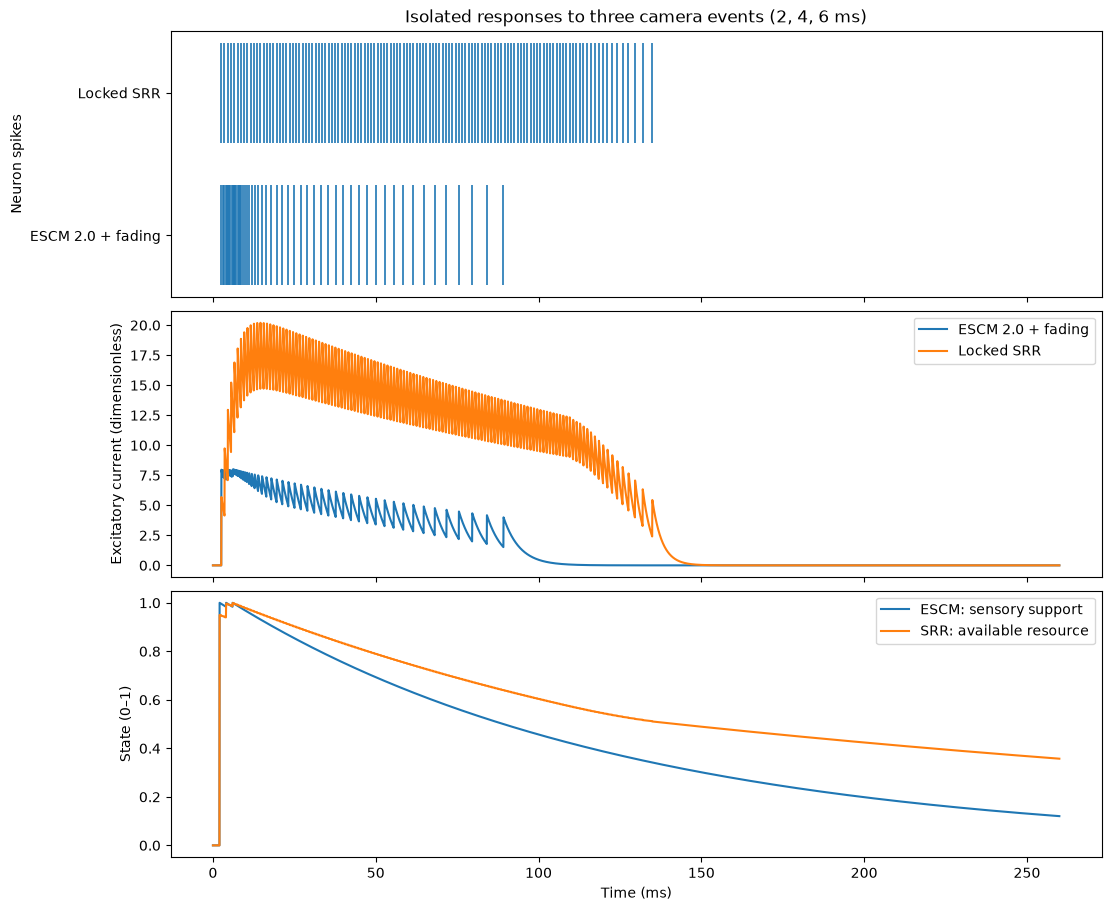

In [5]:
solo_schedule = pulse_schedule(np.array([0]))

def solo_metrics(run):
    t = run["t"]
    isi = np.diff(t)
    return dict(total_spikes=len(t),
                last_spike_ms=float(t[-1]) if len(t) else 0.,
                post_camera_spikes=int(np.count_nonzero(t >= 10.)),
                spikes_30_60=int(np.count_nonzero((t >= 30) & (t < 60))),
                spikes_60_120=int(np.count_nonzero((t >= 60) & (t < 120))),
                spikes_180_260=int(np.count_nonzero((t >= 180) & (t < 260))),
                min_isi_ms=float(isi.min()) if len(isi) else np.nan)

isolated = {}
for name, cfg in [('ESCM 2.0 + fading', reference), ('Locked SRR', candidate)]:
    isolated[name] = simulate(solo_schedule, **cfg, n_neurons=1,
                              duration_ms=260., trace_ids=[0])
solo_summary = pd.DataFrame([dict(model=k, **solo_metrics(v)) for k,v in isolated.items()])
display(solo_summary.round(3))
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True, constrained_layout=True)
for name, out in isolated.items():
    ax[0].vlines(out['t'], 0 if name.startswith('ESCM') else 1,
                 0.7 if name.startswith('ESCM') else 1.7,
                 label=name, linewidth=1.2)
    ax[1].plot(out['time'], out['Iexc'][0], label=name)
    if 'resource' in out:
        ax[2].plot(out['time'], out['resource'][0], label='SRR: available resource')
    else:
        ax[2].plot(out['time'], out['support'][0], label='ESCM: sensory support')
ax[0].set(yticks=[.35, 1.35], yticklabels=list(isolated), ylabel='Neuron spikes',
          title='Isolated responses to three camera events (2, 4, 6 ms)')
ax[1].set(ylabel='Excitatory current (dimensionless)')
ax[2].set(xlabel='Time (ms)', ylabel='State (0–1)')
ax[1].legend(); ax[2].legend()
plt.show()


## 5. Development checks: two geometries, six onset/stagger challenges each

These **are the cases used in calibration**, so passing them is evidence of correct reproduction of the candidate, *not held-out generalization*. The strict success rule requires all five old pixels to fire in the old-only control, all five new pixels to fire in the new-only control, all five old pixels to become silent with competition, all five new pixels to stay active, and no off-target firing. Each decision uses two 10 ms windows offset from the new stimulus onset.


In [6]:
def counts(run, ids, a, b):
    mask = (run["t"] >= a) & (run["t"] < b)
    return np.bincount(run["i"][mask], minlength=n)[ids]

def evaluate(geometry, cfg, *, onset=20., stagger=0., dt=dt_ms):
    old, new = shapes[geometry]
    old_schedule = pulse_schedule(old, second_start=onset, stagger=stagger)
    new_schedule = [(new, (onset, onset+2., onset+4.), stagger)]
    duration = max(100., onset+50.+4*stagger)
    old_only = simulate(old_schedule, **cfg, duration_ms=duration, dt=dt)
    new_only = simulate(new_schedule, **cfg, duration_ms=duration, dt=dt)
    combined = simulate(old_schedule+new_schedule, **cfg, duration_ms=duration, dt=dt)
    intervals = [(onset+12.+4*stagger, onset+22.+4*stagger),
                 (onset+22.+4*stagger, onset+32.+4*stagger)]
    outside = np.setdiff1d(np.arange(n), np.r_[old, new])
    def across_windows(run, ids):
        return np.array([counts(run, ids, a, b) for a, b in intervals])
    old_control = (across_windows(old_only, old) >= 2).all(axis=0)
    new_control = (across_windows(new_only, new) >= 2).all(axis=0)
    old_silent = (across_windows(combined, old) == 0).all(axis=0)
    new_active = (across_windows(combined, new) >= 2).all(axis=0)
    off_target = (across_windows(combined, outside) > 0).any(axis=0)
    eligible = bool(old_control.all() and new_control.all())
    passed = bool(eligible and old_silent.all() and new_active.all() and not off_target.any())
    old_spikes_after_onset = combined["t"][(combined["t"] >= onset) &
                                            np.isin(combined["i"], old)]
    last_old_spike = float(old_spikes_after_onset[-1]) if len(old_spikes_after_onset) else np.nan
    return dict(geometry=geometry, eligible=eligible, success=passed,
                old_control=int(old_control.sum()), new_control=int(new_control.sum()),
                old_silent=int(old_silent.sum()), new_active=int(new_active.sum()),
                off_target=int(off_target.sum()), last_old_spike_ms=last_old_spike)

def geometry_table(cfg, geometry_names, **kwargs):
    return pd.DataFrame([evaluate(name, cfg, **kwargs) for name in geometry_names])

development_cases = [(16., 0.), (20., 0.), (20., .25),
                     (20., .5), (20., 1.), (28., 0.)]
dev_rows = []
for geometry in tqdm(development, desc='Development geometries'):
    for onset, stagger in development_cases:
        for model, cfg in [('ESCM 2.0 + fading', reference), ('Locked SRR', candidate)]:
            dev_rows.append(dict(model=model, **evaluate(geometry, cfg,
                                    onset=onset, stagger=stagger), onset_ms=onset,
                                 stagger_ms=stagger))
dev_table = pd.DataFrame(dev_rows)
display(dev_table.groupby('model')[['eligible', 'success']].sum())
display(dev_table[dev_table.model == 'Locked SRR'][
    ['geometry','onset_ms','stagger_ms','eligible','success','old_silent','new_active','off_target']])


Development geometries:   0%|          | 0/2 [00:00<?, ?it/s]WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 5. * msecond, but the name also refers to a variable in the run namespace with value '3.0'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    The name "tau_exc" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 3. * msecond, but t

,eligible,success
model,,
ESCM 2.0 + fading,12,12
Locked SRR,12,12


,geometry,onset_ms,stagger_ms,eligible,success,old_silent,new_active,off_target
1,vertical,16.0,0.00,True,True,5,5,0
3,vertical,20.0,0.00,True,True,5,5,0
5,vertical,20.0,0.25,True,True,5,5,0
7,vertical,20.0,0.50,True,True,5,5,0
9,vertical,20.0,1.00,True,True,5,5,0
11,vertical,28.0,0.00,True,True,5,5,0
13,horizontal,16.0,0.00,True,True,5,5,0
15,horizontal,20.0,0.00,True,True,5,5,0
17,horizontal,20.0,0.25,True,True,5,5,0
19,horizontal,20.0,0.50,True,True,5,5,0


## 6. Locked spatial generalization — six previously unused geometries

Neither the SRR parameters nor ESCM 2.0 parameters are changed here. The six validation shapes **were not used to select the locked candidate**. For each geometry run old-only, new-only and combined stimuli. Report both strict success and the component counts to distinguish insufficient persistence from insufficient inhibition.


Locked spatial generalization:   0%|          | 0/8 [00:00<?, ?it/s]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line

,model,split,geometry,eligible,success,old_control,new_control,old_silent,new_active,off_target
0,ESCM 2.0 + fading,development,vertical,True,True,5,5,5,5,0
1,Locked SRR,development,vertical,True,True,5,5,5,5,0
2,ESCM 2.0 + fading,development,horizontal,True,True,5,5,5,5,0
3,Locked SRR,development,horizontal,True,True,5,5,5,5,0
4,ESCM 2.0 + fading,validation,diagonal,True,False,5,5,4,5,0
5,Locked SRR,validation,diagonal,True,False,5,5,3,5,0
6,ESCM 2.0 + fading,validation,L-shaped,True,False,5,5,5,4,0
7,Locked SRR,validation,L-shaped,False,False,3,5,2,4,0
8,ESCM 2.0 + fading,validation,stepped,True,True,5,5,5,5,0
9,Locked SRR,validation,stepped,True,False,5,5,1,4,0


eligible  success
model             split                         
ESCM 2.0 + fading development         2        2
                  validation          5        2
Locked SRR        development         2        2
                  validation          4        0

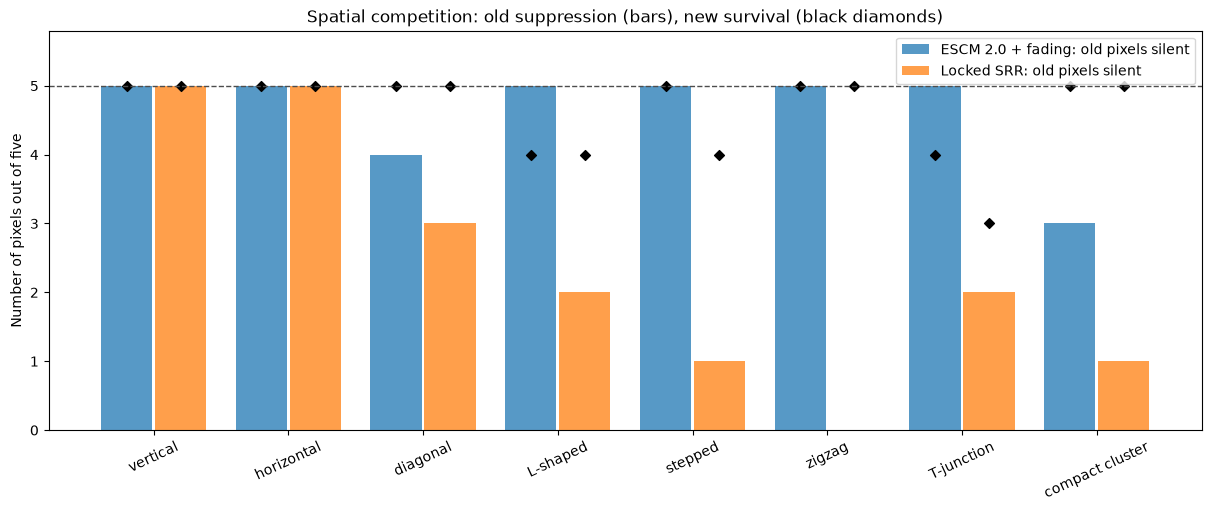

In [7]:
spatial_rows = []
for geometry in tqdm(shapes, desc='Locked spatial generalization'):
    for model, cfg in [('ESCM 2.0 + fading', reference), ('Locked SRR', candidate)]:
        spatial_rows.append(dict(model=model, split=('development' if geometry in development else 'validation'),
                                 **evaluate(geometry, cfg)))
spatial = pd.DataFrame(spatial_rows)
display(spatial[['model','split','geometry','eligible','success','old_control','new_control',
                 'old_silent','new_active','off_target']])
display(spatial.groupby(['model','split'])[['eligible','success']].sum())

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
order = list(shapes)
x = np.arange(len(order))
for offset, (model, color) in zip((-.2,.2), [('ESCM 2.0 + fading','C0'),('Locked SRR','C1')]):
    rows = spatial.set_index(['model','geometry']).loc[[(model,g) for g in order]]
    ax.bar(x+offset, rows.old_silent.values, width=.38,
           label=f'{model}: old pixels silent', color=color, alpha=.75)
    ax.scatter(x+offset, rows.new_active.values, marker='D', color='black', s=25)
ax.axhline(5, color='0.3', linestyle='--', linewidth=1)
ax.set(xticks=x, xticklabels=order, ylim=(0,5.8),
       ylabel='Number of pixels out of five',
       title='Spatial competition: old suppression (bars), new survival (black diamonds)')
ax.tick_params(axis='x', rotation=25)
ax.legend(loc='upper right')
plt.show()


## 7. Temporal generalization on the vertical edge

Report all 16 timing conditions from Notebook 30. Some were used in development calibration (16/20/28 ms), so this is **robustness analysis**, not fully independent temporal validation. The **40 ms onset** is outside the development time grid. The full set is useful for comparison with ESCM 2.0, provided that distinction is kept explicit.


Temporal robustness:   0%|          | 0/16 [00:00<?, ?it/s]WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iex

,eligible,success
model,,
ESCM 2.0 + fading,13,13
Locked SRR,12,11


,model,onset_ms,stagger_ms,eligible,success,old_control,new_control,old_silent,new_active
0,ESCM 2.0 + fading,16.0,0.00,True,True,5,5,5,5
1,Locked SRR,16.0,0.00,True,True,5,5,5,5
2,ESCM 2.0 + fading,16.0,0.25,True,True,5,5,5,5
3,Locked SRR,16.0,0.25,True,True,5,5,5,5
4,ESCM 2.0 + fading,16.0,0.50,True,True,5,5,5,5
5,Locked SRR,16.0,0.50,True,True,5,5,5,5
6,ESCM 2.0 + fading,16.0,1.00,True,True,5,5,5,5
7,Locked SRR,16.0,1.00,True,False,5,5,4,5
8,ESCM 2.0 + fading,20.0,0.00,True,True,5,5,5,5
9,Locked SRR,20.0,0.00,True,True,5,5,5,5


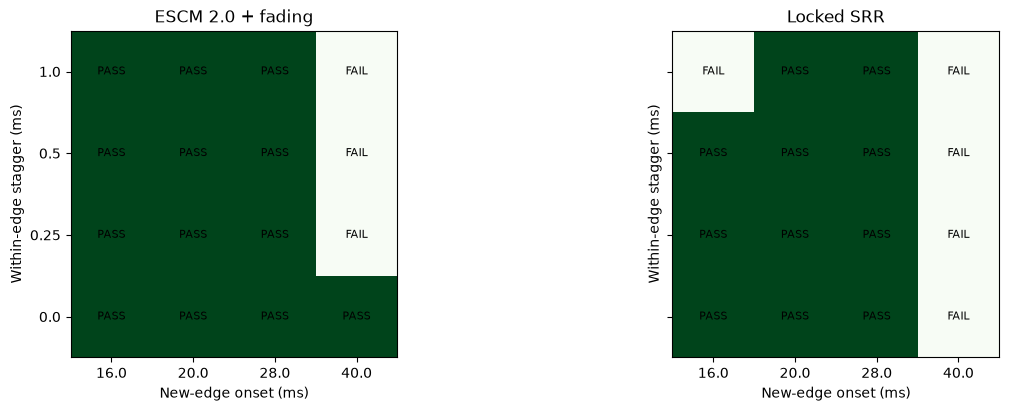

In [8]:
timing_rows = []
for onset, stagger in tqdm(list(product((16.,20.,28.,40.), (0.,.25,.5,1.))),
                           desc='Temporal robustness'):
    for model, cfg in [('ESCM 2.0 + fading', reference), ('Locked SRR', candidate)]:
        timing_rows.append(dict(model=model, onset_ms=onset, stagger_ms=stagger,
                                **evaluate('vertical', cfg, onset=onset, stagger=stagger)))
timing = pd.DataFrame(timing_rows)
display(timing.groupby('model')[['eligible','success']].sum())
display(timing[['model','onset_ms','stagger_ms','eligible','success',
                'old_control','new_control','old_silent','new_active']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True, sharex=True, sharey=True)
for ax, model in zip(axes, timing.model.unique()):
    sub = timing[timing.model==model]
    mat = sub.pivot(index='stagger_ms', columns='onset_ms', values='success')
    ax.imshow(mat.values.astype(float), vmin=0, vmax=1, origin='lower', cmap='Greens')
    ax.set(title=model, xticks=range(len(mat.columns)), xticklabels=mat.columns,
           yticks=range(len(mat.index)), yticklabels=mat.index,
           xlabel='New-edge onset (ms)', ylabel='Within-edge stagger (ms)')
    for i in range(len(mat.index)):
        for j in range(len(mat.columns)):
            ax.text(j,i,'PASS' if mat.iloc[i,j] else 'FAIL',ha='center',va='center',fontsize=8)
plt.show()


## 8. Numerical robustness and mechanism traces

Repeat held-out shapes at $\Delta t\in\{0.1,0.05,0.025\}\,$ms with **all parameters fixed**; this checks classification stability, not identical spike timing. Then inspect one representative old and new pixel in the vertical competition experiment. Resource and current traces explain failure modes that cannot be understood from pass/fail counts alone.


Timestep robustness:   0%|          | 0/3 [00:00<?, ?it/s]WARNING    'i' is an internal variable of group 'synapses', but also exists in the run namespace with the value 3. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]
WARNING    Came across an abstract code block that may 

eligible  success
model             dt_ms                   
ESCM 2.0 + fading 0.025         5        2
                  0.050         5        2
                  0.100         5        2
Locked SRR        0.025         4        0
                  0.050         4        0
                  0.100         4        0

WARNING    Came across an abstract code block that may not be well-defined: the outcome may depend on the order of execution. You can ignore this warning if you are sure that the order of operations does not matter. 2 lines of abstract code, first line is: 'Iexc_post += _lio_1 * resource_post (in-place)'
 [brian2.codegen.generators.base]


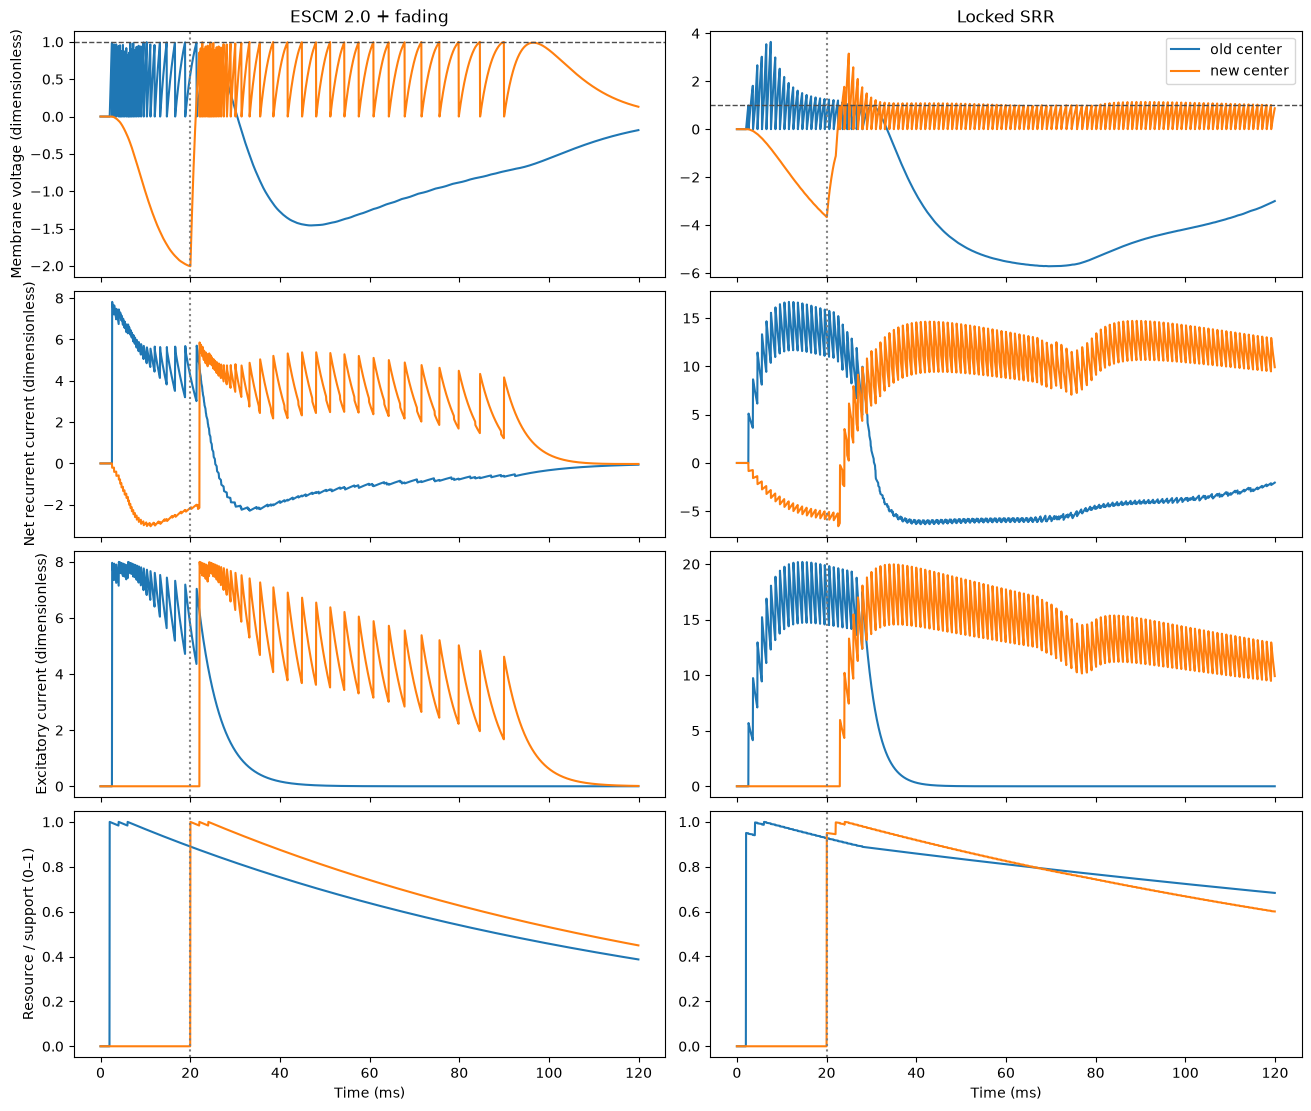

In [9]:
resolution_rows = []
for dt in tqdm((.1,.05,.025), desc='Timestep robustness'):
    for geometry in validation:
        for model, cfg in [('ESCM 2.0 + fading', reference), ('Locked SRR', candidate)]:
            resolution_rows.append(dict(dt_ms=dt, model=model,
                                        **evaluate(geometry,cfg,dt=dt)))
resolution = pd.DataFrame(resolution_rows)
display(resolution.groupby(['model','dt_ms'])[['eligible','success']].sum())

old, new = shapes['vertical']
trace_ids = [int(old[2]), int(new[2])]
traces = {name: simulate(pulse_schedule(old,new), **cfg,
                         duration_ms=120., trace_ids=trace_ids)
          for name,cfg in [('ESCM 2.0 + fading',reference),('Locked SRR',candidate)]}
fig, axes = plt.subplots(4, 2, figsize=(13, 11), sharex=True, constrained_layout=True)
for col, (name, out) in enumerate(traces.items()):
    t=out['time']
    for k, label in enumerate(('old center','new center')):
        axes[0,col].plot(t,out['v'][k],label=label)
        axes[1,col].plot(t,out['Iexc'][k]-out['Iinh'][k],label=label)
        axes[2,col].plot(t,out['Iexc'][k],label=label)
        state='resource' if name=='Locked SRR' else 'support'
        axes[3,col].plot(t,out[state][k],label=label)
    axes[0,col].axhline(1.,linestyle='--',color='0.3',lw=1)
    for ax in axes[:,col]:ax.axvline(20.,linestyle=':',color='0.5')
    axes[0,col].set_title(name)
for row,label in enumerate(('Membrane voltage (dimensionless)',
                            'Net recurrent current (dimensionless)',
                            'Excitatory current (dimensionless)',
                            'Resource / support (0–1)')):
    axes[row,0].set_ylabel(label)
for ax in axes[-1,:]:ax.set_xlabel('Time (ms)')
axes[0,1].legend()
plt.show()


## 9. Interpret the outcome

The central falsifiable prediction is that the selected SRR configuration can temporarily sustain autonomous firing and achieve development replacement **without** ESCM 2.0's overwritten recurrent current or explicit support variable. The independent surrogate reproduced ESCM 2.0's 89.2 ms isolated last spike and found **12/12 development challenges** successful for SRR, but that is not yet a Brian2 result.

The previously untouched spatial geometries are more demanding: the surrogate predicts **2/8 overall spatial successes for SRR versus 4/8 for ESCM 2.0**. Thus even if Brian2 confirms the candidate, it **does not yet outperform the benchmark spatially**. The expected timing result is **11/16 strict SRR successes versus 13/16 for ESCM 2.0**, with important late-onset control failures. Verify or reject these predictions above.

**If Brian2 disagrees with the surrogate:** examine (i) the order of current increment and resource depletion; (ii) exact Brian2 refractory semantics; (iii) synapse scheduling relative to camera spikes and inhibition; and (iv) timestep rounding. Do not optimize on the held-out geometries retroactively and continue calling them held-out.

**Physical interpretation:** An additive synapse with $U=0.0025$ and $J_0=2400$ is a low-utilization synapse with a maximum event impulse of $6$ in the chosen dimensionless units; it is not evidence of an enormous physiological conductance. The fitted inhibitory gain of $4$ and decay of $7$ ms differ from the approved reference, while its inhibition **spatial graph** is unchanged. The synaptic resource is a sensory-modulated, use-depleted phenomenological state, not canonical spontaneously recovering STD.

**Verification status:** exact mathematical bounds and a separate finite-step solver tested here; **Brian2 comparison requires running this notebook**. Neither the finite sweep nor development successes prove universal generalization.
